In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [3]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/EC_Classification/AUG',
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 1074 files belonging to 3 classes.


In [4]:
class_names = dataset.class_names

In [5]:
def flatten_dataset(dataset):
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')
            img_flattened = img_array.flatten()
            flat_data.append(img_flattened)
            target_data.append(label.numpy())
    return np.array(flat_data), np.array(target_data)

In [6]:
train_size = int(0.85 * len(dataset))
test_size = int(0.15 * len(dataset))

In [7]:
train_ds = dataset.take(train_size)
test_ds = dataset.skip(train_size).take(test_size)

In [8]:
x_train, y_train = flatten_dataset(train_ds)
x_test, y_test = flatten_dataset(test_ds)

In [9]:
rf = RandomForestClassifier(random_state=90)
rf.fit(x_train, y_train)

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='auto',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, n_estimators=100,
                       n_jobs=None, oob_score=False, random_state=90, verbose=0,
                       warm_start=False)

In [10]:
y_pred1 = rf.predict(x_test)
accuracy1 = accuracy_score(y_pred1, y_test)
print("The model is {:.2f}% accurate".format(accuracy1 * 100))

The model is 90.62% accurate


In [11]:
report = classification_report(y_test, y_pred1, target_names=class_names)
print("Classification Report:\n\n", report)

Classification Report:

               precision    recall  f1-score   support

   Dysplasia       0.91      0.94      0.93        67
      Normal       0.91      0.87      0.89        47
         SCC       0.89      0.89      0.89        46

    accuracy                           0.91       160
   macro avg       0.91      0.90      0.90       160
weighted avg       0.91      0.91      0.91       160



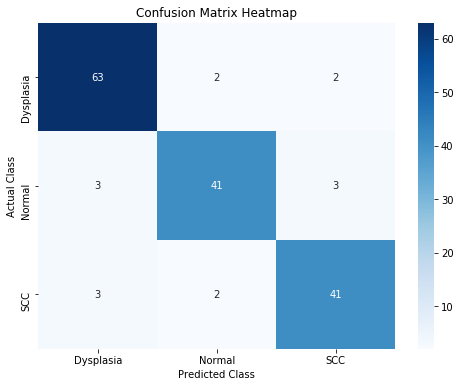

In [12]:
cm = confusion_matrix(y_test, y_pred1)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [14]:
import pickle
with open('/home/smartcity_sp7/EC_Classification/rf_model(WLI).pkl', 'wb') as f:
    pickle.dump(rf, f)

In [15]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

In [20]:
param_grid = {'n_estimators': [100, 200, 300, 400], 'min_samples_leaf': [2, 3, 4, 5]}
clf = GridSearchCV(rf, param_grid, cv=StratifiedKFold(n_splits=6))
model = clf.fit(x_train, y_train)

In [21]:
y_pred2 = clf.predict(x_test)

In [22]:
accuracy2 = accuracy_score(y_pred2, y_test)
print("The model is {:.2f}% accurate".format(accuracy2 * 100))

The model is 90.00% accurate


In [23]:
print("Validation metrics for Hyperparameter Tuning:")
print(classification_report(y_true=y_test, y_pred=y_pred2, target_names=class_names))

Validation metrics for Hyperparameter Tuning:
              precision    recall  f1-score   support

   Dysplasia       0.89      0.94      0.91        67
      Normal       0.91      0.85      0.88        47
         SCC       0.91      0.89      0.90        46

    accuracy                           0.90       160
   macro avg       0.90      0.89      0.90       160
weighted avg       0.90      0.90      0.90       160



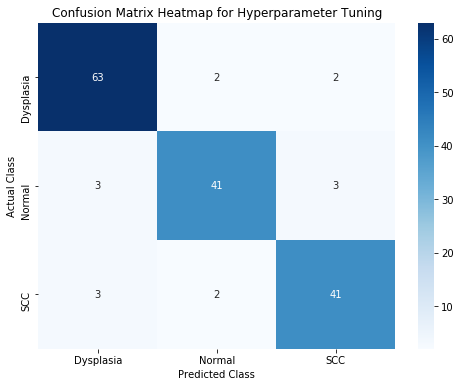

In [25]:
cm = confusion_matrix(y_test, y_pred1)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap for Hyperparameter Tuning")
plt.show()

In [26]:
import pickle
with open('/home/smartcity_sp7/EC_Classification/clf_model(WLI).pkl', 'wb') as f:
    pickle.dump(clf, f)